In [26]:
import os
import sys
import platform
import random
import importlib.metadata
from pathlib import Path

import numpy as np
import cv2
import scipy
import sklearn
import matplotlib
import tensorflow as tf
import keras

PYTHON_VERSION = platform.python_version()
TF_VERSION = tf.__version__
KERAS_VERSION = keras.__version__

IS_COLAB = (
    "google.colab" in sys.modules
    or "COLAB_RELEASE_TAG" in os.environ
)

GPU_DEVICES = tf.config.list_physical_devices("GPU")

print("=" * 65)
print("Realtime Skin Analyst — Environment")
print("=" * 65)
print(f"Python:       {PYTHON_VERSION}")
print(f"Platform:     {platform.platform()}")
print(f"TensorFlow:   {TF_VERSION}")
print(f"Keras:        {KERAS_VERSION}")
print(f"NumPy:        {np.__version__}")
print(f"OpenCV:       {cv2.__version__}")
print(f"SciPy:        {scipy.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"Matplotlib:   {matplotlib.__version__}")
print(f"Colab:        {IS_COLAB}")
print(f"GPU devices:  {GPU_DEVICES}")

KERAS_MAJOR = int(KERAS_VERSION.split(".")[0])
assert KERAS_MAJOR == 3, (
    f"Keras 3 is required; detected Keras {KERAS_VERSION}. "
    "Use a compatible Python environment with TensorFlow 2.17+ and Keras 3."
)

TF_MAJOR, TF_MINOR = map(int, TF_VERSION.split(".")[:2])
assert (TF_MAJOR, TF_MINOR) >= (2, 17), (
    f"TensorFlow 2.17+ is required; detected {TF_VERSION}."
)

if not GPU_DEVICES:
    print(
        "\nNOTICE: No GPU is visible. The notebook will use CPU execution. "
        "Training may be slow."
    )
elif IS_COLAB:
    print("\nColab GPU detected. Training can use the available accelerator.")

print("\nEnvironment checks passed.")

Realtime Skin Analyst — Environment
Python:       3.13.15
Platform:     Linux-6.18.48+-x86_64-with-glibc2.39
TensorFlow:   2.20.0
Keras:        3.13.2
NumPy:        2.1.3
OpenCV:       4.14.0
SciPy:        1.16.3
scikit-learn: 1.6.1
Matplotlib:   3.10.0
Colab:        True
GPU devices:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Colab GPU detected. Training can use the available accelerator.

Environment checks passed.


In [27]:
from dataclasses import dataclass, asdict
from typing import Optional, Sequence, Any
import json
import time
import math

# ---------------------------------------------------------------------
# Paths: relative to the notebook's current working directory
# ---------------------------------------------------------------------
PROJECT_ROOT = Path.cwd()
DATA_DIR = "/kaggle/input/datasets/tejaswinirj/skin-type/skin_type"
OUTPUT_DIR = PROJECT_ROOT / "models" / "package_a"

# Optional webcam face-crop folders. Empty string means unused.
WEBCAM_TEST_DIR = ""
WEBCAM_TRAIN_DIR = ""

# Image-file prediction settings
IMAGE_PATH = ""                    # One image or a directory; empty disables prediction
IMAGES_ARE_FACE_CROPS = False
IMAGE_RESULTS_CSV = OUTPUT_DIR / "image_predictions.csv"

# ---------------------------------------------------------------------
# Execution modes
# ---------------------------------------------------------------------
RUN_TRAINING = True
QUICK_MODE = False
RESUME = False
RUN_PHASE2 = True

# ---------------------------------------------------------------------
# Reproducibility and dataset handling
# ---------------------------------------------------------------------
RANDOM_SEED = 42
BATCH_SIZE = 32
DEBUG_LIMIT_PER_CLASS: Optional[int] = None

# QUICK_MODE uses smaller values for a pipeline smoke test.
QUICK_IMAGES_PER_CLASS = 12
QUICK_PHASE1_EPOCHS = 2
QUICK_PHASE2_EPOCHS = 1

# ---------------------------------------------------------------------
# Model and training
# ---------------------------------------------------------------------
IMAGE_HEIGHT = 224
IMAGE_WIDTH = 224
IMAGE_CHANNELS = 3
INPUT_SHAPE = (IMAGE_HEIGHT, IMAGE_WIDTH, IMAGE_CHANNELS)
INPUT_DTYPE = "float32"
INPUT_MIN = 0.0
INPUT_MAX = 255.0
INPUT_RANGE_DESCRIPTION = "0-255 RGB float32"

CLASS_NAMES = ("dry", "normal", "oily")
FOLDER_TO_CLASS = {
    "dry_data": "dry",
    "normal_data": "normal",
    "oily_data": "oily",
}
WEBCAM_FOLDER_TO_CLASS = {
    "dry": "dry",
    "normal": "normal",
    "oily": "oily",
}
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}

WEIGHTS = "imagenet"                # "none" is only for smoke tests
DROPOUT_RATE = 0.30
PHASE1_EPOCHS = 25
PHASE2_EPOCHS = 15
PHASE1_LEARNING_RATE = 1e-3
PHASE2_LEARNING_RATE = 1e-5
UNFROZEN_BACKBONE_LAYERS = 40
EARLY_STOPPING_PATIENCE = 4
LR_REDUCTION_PATIENCE = 2

# Duplicate similarity thresholds
DUPLICATE_GROUP_THRESHOLD = 0.95
CROSS_LABEL_CONFLICT_THRESHOLD = 0.985
MAX_CONFLICT_DROP_FRACTION = 0.10

# Validation-only calibration and acceptance policy
TARGET_ACCEPTED_ACCURACY = 0.90
MIN_ACCEPTED_COVERAGE = 0.50
CONFIDENCE_THRESHOLD_MIN = 0.40
CONFIDENCE_THRESHOLD_MAX = 0.95
CONFIDENCE_THRESHOLD_STEP = 0.01
FALLBACK_CONFIDENCE_THRESHOLD = 0.60
DEFAULT_TEMPERATURE = 1.0
DEFAULT_MARGIN_THRESHOLD = 0.15
DEFAULT_MIN_AGREEMENT = 0.60
DEFAULT_VOTING_WINDOW = 20
DEFAULT_MIN_VOTES = 8
DEFAULT_CLASSIFY_EVERY_N_GOOD_FRAMES = 3
MISSING_FACE_RESET_FRAMES = 20

# ---------------------------------------------------------------------
# Webcam settings
# ---------------------------------------------------------------------
CAMERA_INDEX = 0
CAMERA_WIDTH = 1280
CAMERA_HEIGHT = 720
COLLECT_MODE = False
WEBCAM_COLLECTION_DIR = PROJECT_ROOT / "data" / "webcam"
MAX_LIVE_RUNTIME_SECONDS = 600
FACE_CROP_MARGIN = 0.15

# ---------------------------------------------------------------------
# Quality gate thresholds: all quality defaults live in one dataclass.
# ---------------------------------------------------------------------
@dataclass(frozen=True)
class QualityThresholds:
    """Centralise quality limits so camera-specific adjustments remain auditable."""

    min_face_width_fraction: float = 0.14
    max_face_width_fraction: float = 0.80
    frame_center_margin_fraction: float = 0.15
    exposure_mean_min: float = 30.0
    exposure_mean_max: float = 225.0
    dark_pixel_cutoff: float = 25.0
    max_dark_pixel_fraction: float = 0.40
    bright_pixel_cutoff: float = 235.0
    max_bright_pixel_fraction: float = 0.12
    min_laplacian_variance: float = 25.0
    max_side_brightness_ratio: float = 2.2
    face_inner_inset_fraction: float = 0.15
    sharpness_size: tuple[int, int] = (128, 128)


@dataclass(frozen=True)
class DecisionThresholds:
    """Separate frame-aggregation policy from image-quality limits."""

    voting_window: int = DEFAULT_VOTING_WINDOW
    minimum_votes: int = DEFAULT_MIN_VOTES
    classify_every_n_good_frames: int = DEFAULT_CLASSIFY_EVERY_N_GOOD_FRAMES
    margin_threshold: float = DEFAULT_MARGIN_THRESHOLD
    agreement_threshold: float = DEFAULT_MIN_AGREEMENT
    missing_face_reset_frames: int = MISSING_FACE_RESET_FRAMES


QUALITY_THRESHOLDS = QualityThresholds()
DECISION_THRESHOLDS = DecisionThresholds()

# Resolve mode-specific settings without overwriting the requested full-run values.
EFFECTIVE_PHASE1_EPOCHS = (
    QUICK_PHASE1_EPOCHS if QUICK_MODE else PHASE1_EPOCHS
)
EFFECTIVE_PHASE2_EPOCHS = (
    QUICK_PHASE2_EPOCHS if QUICK_MODE else PHASE2_EPOCHS
)
EFFECTIVE_DEBUG_LIMIT = (
    QUICK_IMAGES_PER_CLASS
    if QUICK_MODE
    else DEBUG_LIMIT_PER_CLASS
)

if WEIGHTS not in {"imagenet", "none"}:
    raise ValueError("WEIGHTS must be either 'imagenet' or 'none'.")

if not 0.0 <= DROPOUT_RATE < 1.0:
    raise ValueError("DROPOUT_RATE must be in the interval [0, 1).")

if not 0.0 < CROSS_LABEL_CONFLICT_THRESHOLD <= 1.0:
    raise ValueError("CROSS_LABEL_CONFLICT_THRESHOLD must be in (0, 1].")

if not 0.0 < DUPLICATE_GROUP_THRESHOLD <= 1.0:
    raise ValueError("DUPLICATE_GROUP_THRESHOLD must be in (0, 1].")

if BATCH_SIZE < 1:
    raise ValueError("BATCH_SIZE must be positive.")

# Seed the libraries used throughout the notebook.
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)
keras.utils.set_random_seed(RANDOM_SEED)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Settings loaded.")
print(f"Dataset folder: {DATA_DIR}")
print(f"Output folder:  {OUTPUT_DIR}")
print(f"Classes/order:  {list(CLASS_NAMES)}")
print(f"Training:       {RUN_TRAINING}")
print(f"Quick mode:     {QUICK_MODE}")
print(f"Phase epochs:   {EFFECTIVE_PHASE1_EPOCHS} + {EFFECTIVE_PHASE2_EPOCHS}")
print(f"Quality limits: {QUALITY_THRESHOLDS}")
print(f"Decision limits:{DECISION_THRESHOLDS}")

Settings loaded.
Dataset folder: /kaggle/input/datasets/tejaswinirj/skin-type/skin_type
Output folder:  /kaggle/working/models/package_a
Classes/order:  ['dry', 'normal', 'oily']
Training:       True
Quick mode:     False
Phase epochs:   25 + 15
Quality limits: QualityThresholds(min_face_width_fraction=0.14, max_face_width_fraction=0.8, frame_center_margin_fraction=0.15, exposure_mean_min=30.0, exposure_mean_max=225.0, dark_pixel_cutoff=25.0, max_dark_pixel_fraction=0.4, bright_pixel_cutoff=235.0, max_bright_pixel_fraction=0.12, min_laplacian_variance=25.0, max_side_brightness_ratio=2.2, face_inner_inset_fraction=0.15, sharpness_size=(128, 128))
Decision limits:DecisionThresholds(voting_window=20, minimum_votes=8, classify_every_n_good_frames=3, margin_threshold=0.15, agreement_threshold=0.6, missing_face_reset_frames=20)


In [28]:
def _validate_bgr_image(image: np.ndarray) -> np.ndarray:
    """Reject malformed images early so corrupt inputs cannot silently reach the model."""
    if not isinstance(image, np.ndarray):
        raise TypeError("Expected an image as a NumPy array.")
    if image.ndim != 3 or image.shape[2] != 3:
        raise ValueError(
            f"Expected a three-channel BGR image; got shape {image.shape}."
        )
    if image.shape[0] < 1 or image.shape[1] < 1:
        raise ValueError("Image height and width must be positive.")
    if image.dtype != np.uint8:
        if not np.issubdtype(image.dtype, np.number):
            raise TypeError("Image pixels must be numeric.")
        if not np.isfinite(image).all():
            raise ValueError("Image contains non-finite pixel values.")
        image = np.clip(image, 0, 255).astype(np.uint8)
    return image


def preprocess_bgr_to_rgb_uint8(
    bgr_image: np.ndarray,
    target_size: tuple[int, int] = (IMAGE_HEIGHT, IMAGE_WIDTH),
) -> np.ndarray:
    """Create the canonical RGB image while preserving the 0–255 pixel range."""
    bgr_image = _validate_bgr_image(bgr_image)
    target_height, target_width = target_size

    if target_height < 1 or target_width < 1:
        raise ValueError("Target dimensions must be positive.")

    source_height, source_width = bgr_image.shape[:2]
    shrinking = (
        target_height < source_height
        or target_width < source_width
    )
    interpolation = cv2.INTER_AREA if shrinking else cv2.INTER_LINEAR

    resized = cv2.resize(
        bgr_image,
        (target_width, target_height),
        interpolation=interpolation,
    )
    rgb_image = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)

    if rgb_image.dtype != np.uint8:
        rgb_image = np.clip(rgb_image, 0, 255).astype(np.uint8)

    return np.ascontiguousarray(rgb_image)


def preprocess_bgr_image(
    bgr_image: np.ndarray,
    target_size: tuple[int, int] = (IMAGE_HEIGHT, IMAGE_WIDTH),
) -> np.ndarray:
    """Return a single model-ready image without external normalisation."""
    rgb_image = preprocess_bgr_to_rgb_uint8(bgr_image, target_size)
    model_input = rgb_image.astype(np.float32, copy=False)
    assert_model_input_range(model_input)
    return model_input


def assert_model_input_range(
    images: np.ndarray,
    *,
    name: str = "model input",
) -> None:
    """Catch accidental 0–1 scaling before it can flatten backbone features."""
    array = np.asarray(images)

    if array.size == 0:
        raise ValueError(f"{name} is empty.")

    if not np.issubdtype(array.dtype, np.number):
        raise TypeError(f"{name} must contain numeric pixel values.")

    if not np.isfinite(array).all():
        raise ValueError(f"{name} contains non-finite values.")

    maximum = float(np.max(array))
    minimum = float(np.min(array))

    if maximum <= 1.5:
        raise ValueError(
            f"{name} has maximum value {maximum:.4f}. "
            "Expected RGB pixel values in the 0–255 range; "
            "possible accidental 0–1 scaling."
        )

    if minimum < 0.0 or maximum > 255.0:
        raise ValueError(
            f"{name} must stay within 0–255; observed "
            f"minimum={minimum:.4f}, maximum={maximum:.4f}."
        )


def make_square_face_crop(
    image: np.ndarray,
    box: tuple[int, int, int, int],
    margin: float = FACE_CROP_MARGIN,
) -> np.ndarray:
    """Pad beyond image borders so every detected face gets a square crop."""
    image = _validate_bgr_image(image)

    if margin < 0:
        raise ValueError("Crop margin cannot be negative.")

    x, y, width, height = map(int, box)
    if width <= 0 or height <= 0:
        raise ValueError(f"Face box must have positive dimensions; got {box}.")

    centre_x = x + width / 2.0
    centre_y = y + height / 2.0
    side = max(1, int(math.ceil(max(width, height) * (1.0 + 2.0 * margin))))

    left = int(math.floor(centre_x - side / 2.0))
    top = int(math.floor(centre_y - side / 2.0))
    right = left + side
    bottom = top + side

    image_height, image_width = image.shape[:2]

    pad_left = max(0, -left)
    pad_top = max(0, -top)
    pad_right = max(0, right - image_width)
    pad_bottom = max(0, bottom - image_height)

    if any((pad_left, pad_top, pad_right, pad_bottom)):
        image = cv2.copyMakeBorder(
            image,
            pad_top,
            pad_bottom,
            pad_left,
            pad_right,
            borderType=cv2.BORDER_REPLICATE,
        )
        left += pad_left
        right += pad_left
        top += pad_top
        bottom += pad_top

    crop = image[top:bottom, left:right]

    if crop.shape[0] != crop.shape[1]:
        raise RuntimeError(
            f"Internal crop error: expected a square, got {crop.shape[:2]}."
        )

    return crop.copy()


print("Shared preprocessing functions defined.")
print("Canonical model input: float32 RGB, shape (224, 224, 3), range 0–255.")

Shared preprocessing functions defined.
Canonical model input: float32 RGB, shape (224, 224, 3), range 0–255.


In [29]:
from scipy.optimize import minimize_scalar
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)


def softmax(logits: np.ndarray, temperature: float = 1.0) -> np.ndarray:
    """Convert logits to stable probabilities without changing the saved model."""
    logits = np.asarray(logits, dtype=np.float64)

    if logits.ndim != 2:
        raise ValueError(f"Expected a 2-D logits array; got {logits.shape}.")
    if logits.shape[0] == 0 or logits.shape[1] < 2:
        raise ValueError("Logits must contain samples and at least two classes.")
    if not np.isfinite(logits).all():
        raise ValueError("Logits contain non-finite values.")
    if not np.isfinite(temperature) or temperature <= 0:
        raise ValueError("Temperature must be finite and strictly positive.")

    scaled = logits / float(temperature)
    shifted = scaled - np.max(scaled, axis=1, keepdims=True)
    exponentials = np.exp(shifted)
    probabilities = exponentials / np.sum(
        exponentials, axis=1, keepdims=True
    )

    return probabilities


def negative_log_likelihood(
    logits: np.ndarray,
    labels: np.ndarray,
    temperature: float = 1.0,
) -> float:
    """Measure the log loss of logits so temperature can be fitted objectively."""
    labels = np.asarray(labels, dtype=np.int64).reshape(-1)
    probabilities = softmax(logits, temperature)

    if len(labels) != len(probabilities):
        raise ValueError("Labels and logits must contain the same number of samples.")
    if np.any(labels < 0) or np.any(labels >= probabilities.shape[1]):
        raise ValueError("Labels contain an invalid class index.")

    chosen = probabilities[np.arange(len(labels)), labels]
    return float(-np.mean(np.log(np.clip(chosen, 1e-12, 1.0))))


def fit_temperature(
    validation_logits: np.ndarray,
    validation_labels: np.ndarray,
    bounds: tuple[float, float] = (0.2, 10.0),
) -> float:
    """Fit one scalar temperature on validation data to reduce negative log-likelihood."""
    lower, upper = bounds

    if lower <= 0 or upper <= lower:
        raise ValueError("Temperature bounds must satisfy 0 < lower < upper.")

    labels = np.asarray(validation_labels, dtype=np.int64).reshape(-1)
    logits = np.asarray(validation_logits)

    if logits.ndim != 2 or len(logits) != len(labels):
        raise ValueError("Validation logits and labels have incompatible shapes.")
    if len(labels) == 0:
        raise ValueError("Cannot fit temperature on an empty validation set.")

    result = minimize_scalar(
        lambda temperature: negative_log_likelihood(
            logits, labels, temperature
        ),
        method="bounded",
        bounds=(float(lower), float(upper)),
        options={"xatol": 1e-4, "maxiter": 500},
    )

    if not result.success or not np.isfinite(result.fun):
        raise RuntimeError(
            f"Temperature fitting failed: {result.message}"
        )

    return float(result.x)


def expected_calibration_error(
    probabilities: np.ndarray,
    labels: np.ndarray,
    n_bins: int = 10,
) -> float:
    """Compare confidence with empirical accuracy in equal-width confidence bins."""
    probabilities = np.asarray(probabilities, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.int64).reshape(-1)

    if probabilities.ndim != 2:
        raise ValueError("Probabilities must be a 2-D array.")
    if len(probabilities) != len(labels) or len(labels) == 0:
        raise ValueError("Labels and probabilities must have equal, nonzero length.")
    if n_bins < 1:
        raise ValueError("n_bins must be positive.")
    if not np.isfinite(probabilities).all():
        raise ValueError("Probabilities contain non-finite values.")
    if np.any(probabilities < 0) or np.any(probabilities > 1):
        raise ValueError("Probabilities must be between 0 and 1.")
    if not np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-5):
        raise ValueError("Each probability row must sum to 1.")

    predictions = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)
    correct = (predictions == labels).astype(np.float64)

    # Bins are [lower, upper), except the final bin includes 1.0.
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0

    for index in range(n_bins):
        lower = bin_edges[index]
        upper = bin_edges[index + 1]

        if index == n_bins - 1:
            in_bin = (confidence >= lower) & (confidence <= upper)
        else:
            in_bin = (confidence >= lower) & (confidence < upper)

        count = int(np.sum(in_bin))
        if count == 0:
            continue

        bin_accuracy = float(np.mean(correct[in_bin]))
        bin_confidence = float(np.mean(confidence[in_bin]))
        ece += (count / len(labels)) * abs(bin_accuracy - bin_confidence)

    return float(ece)


def select_confidence_threshold(
    probabilities: np.ndarray,
    labels: np.ndarray,
    target_accuracy: float = TARGET_ACCEPTED_ACCURACY,
    min_coverage: float = MIN_ACCEPTED_COVERAGE,
    threshold_min: float = CONFIDENCE_THRESHOLD_MIN,
    threshold_max: float = CONFIDENCE_THRESHOLD_MAX,
    threshold_step: float = CONFIDENCE_THRESHOLD_STEP,
    fallback: float = FALLBACK_CONFIDENCE_THRESHOLD,
) -> tuple[float, bool]:
    """Choose the least restrictive qualifying threshold without consulting test labels."""
    probabilities = np.asarray(probabilities, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.int64).reshape(-1)

    if probabilities.ndim != 2 or len(probabilities) != len(labels):
        raise ValueError("Probabilities and labels have incompatible shapes.")
    if len(labels) == 0:
        raise ValueError("Cannot select a threshold on an empty validation set.")
    if not 0.0 <= target_accuracy <= 1.0:
        raise ValueError("target_accuracy must be between 0 and 1.")
    if not 0.0 < min_coverage <= 1.0:
        raise ValueError("min_coverage must be in (0, 1].")
    if threshold_step <= 0 or threshold_max < threshold_min:
        raise ValueError("Invalid confidence threshold range.")
    if not np.isfinite(probabilities).all():
        raise ValueError("Probabilities contain non-finite values.")

    predictions = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)

    # Integer step counting avoids floating-point drift across thresholds.
    n_steps = int(
        math.floor(
            (threshold_max - threshold_min) / threshold_step + 1e-9
        )
    )
    candidates = [
        round(threshold_min + i * threshold_step, 10)
        for i in range(n_steps + 1)
    ]

    for threshold in candidates:
        accepted = confidence >= threshold
        coverage = float(np.mean(accepted))

        if coverage < min_coverage or not np.any(accepted):
            continue

        accepted_accuracy = float(
            np.mean(predictions[accepted] == labels[accepted])
        )

        if accepted_accuracy >= target_accuracy:
            return float(threshold), True

    return float(fallback), False


def summarize_classification(
    probabilities: np.ndarray,
    labels: np.ndarray,
    class_names: Sequence[str] = CLASS_NAMES,
    confidence_threshold: float = FALLBACK_CONFIDENCE_THRESHOLD,
) -> dict[str, Any]:
    """Build consistent evaluation statistics for reports and notebook displays."""
    probabilities = np.asarray(probabilities, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.int64).reshape(-1)

    if probabilities.ndim != 2 or len(probabilities) != len(labels):
        raise ValueError("Probabilities and labels have incompatible shapes.")
    if len(labels) == 0:
        raise ValueError("Cannot evaluate an empty dataset.")
    if probabilities.shape[1] != len(class_names):
        raise ValueError("Class names do not match the probability output size.")

    predictions = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)
    accepted = confidence >= confidence_threshold

    precision, recall, f1, support = precision_recall_fscore_support(
        labels,
        predictions,
        labels=np.arange(len(class_names)),
        zero_division=0,
    )

    accepted_accuracy = (
        float(np.mean(predictions[accepted] == labels[accepted]))
        if np.any(accepted)
        else None
    )

    return {
        "accuracy": float(accuracy_score(labels, predictions)),
        "per_class": {
            name: {
                "precision": float(precision[index]),
                "recall": float(recall[index]),
                "f1": float(f1[index]),
                "support": int(support[index]),
            }
            for index, name in enumerate(class_names)
        },
        "confusion_matrix": confusion_matrix(
            labels,
            predictions,
            labels=np.arange(len(class_names)),
        ).tolist(),
        "mean_confidence": float(np.mean(confidence)),
        "expected_calibration_error": expected_calibration_error(
            probabilities, labels, n_bins=10
        ),
        "confidence_threshold": float(confidence_threshold),
        "coverage": float(np.mean(accepted)),
        "accepted_accuracy": accepted_accuracy,
        "accepted_count": int(np.sum(accepted)),
        "total_count": int(len(labels)),
    }


print("Metrics helpers defined.")
print("Temperature bounds: 0.2 to 10.0")
print("Expected calibration error: 10 bins")
print("Confidence selection: validation-only threshold search")

Metrics helpers defined.
Temperature bounds: 0.2 to 10.0
Expected calibration error: 10 bins
Confidence selection: validation-only threshold search


In [30]:
if RUN_TRAINING:
    import hashlib
    import warnings
    import pandas as pd
    from collections import defaultdict
    from pathlib import Path

    SUPPORTED_IMAGE_EXTENSIONS = {
        ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"
    }

    def read_image_unicode_safe(path: str | Path) -> np.ndarray:
        """Read image bytes explicitly because Windows imread can mishandle Unicode paths."""
        path = Path(path)
        try:
            raw = np.fromfile(str(path), dtype=np.uint8)
            if raw.size == 0:
                raise ValueError("file is empty")
            image = cv2.imdecode(raw, cv2.IMREAD_COLOR)
            if image is None:
                raise ValueError("OpenCV could not decode the image")
            return image
        except Exception as exc:
            raise ValueError(f"Could not read image '{path}': {exc}") from exc

    def md5_file(path: str | Path) -> str:
        """Hash the original bytes so byte-identical files can be identified reliably."""
        digest = hashlib.md5()
        with Path(path).open("rb") as file_handle:
            for block in iter(lambda: file_handle.read(1024 * 1024), b""):
                digest.update(block)
        return digest.hexdigest()

    def resolve_class_folder(path: Path) -> Optional[str]:
        """Find the nearest recognised class folder, ignoring train/validation labels."""
        for parent in path.parents:
            if parent.name in FOLDER_TO_CLASS:
                return FOLDER_TO_CLASS[parent.name]
            if parent.name in WEBCAM_FOLDER_TO_CLASS:
                return WEBCAM_FOLDER_TO_CLASS[parent.name]
        return None

    def scan_image_records(
        data_dir: str | Path,
        webcam_train_dir: str | Path | None = None,
        debug_limit_per_class: int | None = None,
    ) -> pd.DataFrame:
        """Collect original images without trusting the dataset's pre-existing split."""
        data_dir = Path(data_dir)
        if not data_dir.is_dir():
            raise FileNotFoundError(
                f"Dataset folder not found: {data_dir.resolve()}. "
                "Set DATA_DIR to the folder containing dry_data, normal_data, "
                "and oily_data."
            )

        candidate_roots = [data_dir]
        if webcam_train_dir:
            extra_root = Path(webcam_train_dir)
            if not extra_root.is_dir():
                raise FileNotFoundError(
                    f"Webcam training folder not found: {extra_root.resolve()}"
                )
            candidate_roots.append(extra_root)

        rows = []
        seen_paths = set()
        per_class_count = defaultdict(int)

        for root in candidate_roots:
            for path in sorted(root.rglob("*")):
                if not path.is_file():
                    continue
                if path.suffix.lower() not in SUPPORTED_IMAGE_EXTENSIONS:
                    continue
                if path.name.lower().startswith("aug_"):
                    continue

                label_name = resolve_class_folder(path)
                if label_name not in CLASS_TO_INDEX:
                    continue

                # Keep optional webcam images identifiable for external evaluation.
                is_webcam = bool(webcam_train_dir) and (
                    Path(webcam_train_dir).resolve() in path.resolve().parents
                    or path.resolve() == Path(webcam_train_dir).resolve()
                )

                resolved = str(path.resolve())
                if resolved in seen_paths:
                    continue

                if (
                    debug_limit_per_class is not None
                    and per_class_count[label_name] >= debug_limit_per_class
                ):
                    continue

                try:
                    file_hash = md5_file(path)
                    bgr = read_image_unicode_safe(path)
                    rgb = preprocess_bgr_to_rgb_uint8(bgr)
                except Exception as exc:
                    warnings.warn(str(exc), RuntimeWarning)
                    continue

                rows.append({
                    "path": resolved,
                    "label": label_name,
                    "label_id": CLASS_TO_INDEX[label_name],
                    "md5": file_hash,
                    "image": rgb,
                    "source": "webcam_train" if is_webcam else "dataset",
                })
                seen_paths.add(resolved)
                per_class_count[label_name] += 1

        if not rows:
            raise ValueError(
                f"No usable class images found under {data_dir.resolve()}. "
                f"Expected class folders named {list(FOLDER_TO_CLASS)} "
                "somewhere under the dataset root."
            )

        frame = pd.DataFrame(rows)
        print(f"Loaded usable images before exact-duplicate removal: {len(frame)}")
        print("Class counts before exact-duplicate removal:")
        print(frame.groupby("label").size().reindex(CLASS_NAMES, fill_value=0))

        return frame

    def remove_exact_duplicates(records: pd.DataFrame) -> pd.DataFrame:
        """Drop duplicate bytes and discard every label-conflicted hash group."""
        if records.empty:
            raise ValueError("Cannot deduplicate an empty dataset.")

        frame = records.copy()
        keep_indices = []
        conflict_hashes = set()
        duplicate_hashes = set()

        for digest, group in frame.groupby("md5", sort=False):
            labels = set(group["label"].tolist())

            if len(labels) > 1:
                conflict_hashes.add(digest)
                continue

            keep_indices.append(group.index[0])
            if len(group) > 1:
                duplicate_hashes.add(digest)

        cleaned = frame.loc[keep_indices].copy().reset_index(drop=True)

        print(f"Exact duplicate hash groups: {len(duplicate_hashes)}")
        print(f"Conflicting-label hash groups dropped: {len(conflict_hashes)}")
        print(f"Images remaining: {len(cleaned)}")
        print("Class counts after exact-duplicate removal:")
        print(cleaned.groupby("label").size().reindex(CLASS_NAMES, fill_value=0))

        if cleaned.empty:
            raise ValueError(
                "All images were removed during exact-duplicate handling. "
                "Check the class-folder labels and source files."
            )

        return cleaned

    records_raw = scan_image_records(
        DATA_DIR,
        webcam_train_dir=WEBCAM_TRAIN_DIR or None,
        debug_limit_per_class=EFFECTIVE_DEBUG_LIMIT,
    )
    records = remove_exact_duplicates(records_raw)

    # Retain a compact uint8 array; float32 conversion happens in tf.data.
    X_images_uint8 = np.stack(records["image"].to_list()).astype(np.uint8)
    y_labels = records["label_id"].to_numpy(dtype=np.int64)

    assert X_images_uint8.shape[1:] == INPUT_SHAPE
    assert X_images_uint8.dtype == np.uint8
    assert set(np.unique(y_labels)).issubset({0, 1, 2})

    print(f"In-memory dataset shape: {X_images_uint8.shape}")
else:
    print("Dataset scanning skipped because RUN_TRAINING=False.")

Loaded usable images before exact-duplicate removal: 642
Class counts before exact-duplicate removal:
label
dry       210
normal    230
oily      202
dtype: int64
Exact duplicate hash groups: 12
Conflicting-label hash groups dropped: 0
Images remaining: 628
Class counts after exact-duplicate removal:
label
dry       198
normal    228
oily      202
dtype: int64
In-memory dataset shape: (628, 224, 224, 3)


In [31]:
from pathlib import Path
import collections
root = Path("/kaggle/input/datasets/tejaswinirj/skin-type/skin_type")
for split in ["train", "validation"]:
    for cls in ["dry_data", "normal_data", "oily_data"]:
        files = [p for p in (root/split/cls).iterdir() if p.is_file()]
        aug = [p for p in files if p.name.startswith("aug_")]
        print(f"{split}/{cls}: total={len(files)}  aug_={len(aug)}  originals={len(files)-len(aug)}")
        prefixes = collections.Counter(p.name.split("_")[0] for p in files)
        print("   most common name prefixes:", prefixes.most_common(3))

train/dry_data: total=300  aug_=132  originals=168
   most common name prefixes: [('aug', 132), ('dry', 87), ('ubah (3).jpg', 1)]
train/normal_data: total=300  aug_=116  originals=184
   most common name prefixes: [('aug', 116), ('normal (109).jpg', 1), ('normal (22).jpg', 1)]
train/oily_data: total=300  aug_=138  originals=162
   most common name prefixes: [('aug', 138), ('oily', 126), ('ubah (3).jpg', 1)]
validation/dry_data: total=42  aug_=0  originals=42
   most common name prefixes: [('ubah (16).j.jpg', 1), ('ubah (48).j.jpg', 1), ('ubah (24).j.jpg', 1)]
validation/normal_data: total=46  aug_=0  originals=46
   most common name prefixes: [('ubah (53).j.jpg', 1), ('ubah (48).j.jpg', 1), ('ubah (36).jpg', 1)]
validation/oily_data: total=40  aug_=0  originals=40
   most common name prefixes: [('ubah (61).jpg', 1), ('ubah (52).jpg', 1), ('ubah (36).jpg', 1)]


In [32]:
if RUN_TRAINING:
    from sklearn.model_selection import StratifiedGroupKFold
    from sklearn.preprocessing import normalize

    def build_embedding_model(weights: str = WEIGHTS) -> keras.Model:
        """Use pooled ImageNet features to detect duplicate content, not predict labels."""
        backbone = keras.applications.EfficientNetV2B0(
            include_top=False,
            weights=weights,
            pooling="avg",
            include_preprocessing=True,
            input_shape=INPUT_SHAPE,
        )
        backbone.trainable = False
        return backbone

    def calculate_embeddings(
        images_uint8: np.ndarray,
        batch_size: int = BATCH_SIZE,
    ) -> np.ndarray:
        """Extract L2-normalised frozen features for duplicate auditing."""
        if images_uint8.ndim != 4 or images_uint8.shape[1:] != INPUT_SHAPE:
            raise ValueError(
                f"Expected images with shape (N, {INPUT_SHAPE}); "
                f"received {images_uint8.shape}."
            )

        embedding_model = build_embedding_model(WEIGHTS)
        features = []

        for start in range(0, len(images_uint8), batch_size):
            batch = images_uint8[start:start + batch_size].astype(np.float32)
            assert_model_input_range(batch, name="embedding input")
            batch_features = embedding_model(batch, training=False).numpy()
            features.append(batch_features)

        embeddings = np.concatenate(features, axis=0)
        embeddings = normalize(embeddings, norm="l2", axis=1)

        del embedding_model
        return embeddings.astype(np.float32)

    class UnionFind:
        """Track connected duplicate groups so transitive near-duplicates stay together."""

        def __init__(self, size: int):
            self.parent = list(range(size))
            self.rank = [0] * size

        def find(self, item: int) -> int:
            if self.parent[item] != item:
                self.parent[item] = self.find(self.parent[item])
            return self.parent[item]

        def union(self, first: int, second: int) -> None:
            root_a = self.find(first)
            root_b = self.find(second)

            if root_a == root_b:
                return

            if self.rank[root_a] < self.rank[root_b]:
                root_a, root_b = root_b, root_a

            self.parent[root_b] = root_a
            if self.rank[root_a] == self.rank[root_b]:
                self.rank[root_a] += 1

    def remove_cross_label_near_duplicates(
        records: pd.DataFrame,
        embeddings: np.ndarray,
        threshold: float = CROSS_LABEL_CONFLICT_THRESHOLD,
    ) -> tuple[pd.DataFrame, np.ndarray]:
        """Drop every image involved in a highly similar pair with conflicting labels."""
        if len(records) != len(embeddings):
            raise ValueError("Embedding count does not match record count.")

        labels = records["label_id"].to_numpy()
        similarities = embeddings @ embeddings.T
        conflict_mask = np.zeros(len(records), dtype=bool)

        upper_i, upper_j = np.triu_indices(len(records), k=1)
        candidate_pairs = (
            (similarities[upper_i, upper_j] >= threshold)
            & (labels[upper_i] != labels[upper_j])
        )

        conflict_i = upper_i[candidate_pairs]
        conflict_j = upper_j[candidate_pairs]

        if len(conflict_i):
            conflict_mask[conflict_i] = True
            conflict_mask[conflict_j] = True

        dropped_fraction = float(np.mean(conflict_mask)) if len(records) else 0.0

        if dropped_fraction > MAX_CONFLICT_DROP_FRACTION:
            raise RuntimeError(
                f"Cross-label near-duplicate checking would drop "
                f"{dropped_fraction:.1%} of images, exceeding the "
                f"{MAX_CONFLICT_DROP_FRACTION:.0%} safety limit. "
                "Likely causes include failed or inappropriate ImageNet weights, "
                "severe label mixing, or a dataset containing many conflicting "
                "copies. Verify labels and confirm that ImageNet weights loaded."
            )

        kept = records.loc[~conflict_mask].copy().reset_index(drop=True)
        kept_embeddings = embeddings[~conflict_mask]

        print(f"Cross-label near-duplicate pairs: {len(conflict_i)}")
        print(f"Images removed by conflict guard: {int(conflict_mask.sum())}")
        print(f"Fraction removed: {dropped_fraction:.2%}")

        if kept.empty:
            raise ValueError("No images remain after cross-label conflict removal.")

        return kept, kept_embeddings

    def assign_duplicate_groups(
        embeddings: np.ndarray,
        threshold: float = DUPLICATE_GROUP_THRESHOLD,
    ) -> np.ndarray:
        """Connect near-duplicates transitively using cosine similarity."""
        if len(embeddings) == 0:
            raise ValueError("Cannot group an empty embedding array.")

        similarities = embeddings @ embeddings.T
        union_find = UnionFind(len(embeddings))

        upper_i, upper_j = np.triu_indices(len(embeddings), k=1)
        close_pairs = similarities[upper_i, upper_j] >= threshold

        for i, j in zip(upper_i[close_pairs], upper_j[close_pairs]):
            union_find.union(int(i), int(j))

        roots = [union_find.find(i) for i in range(len(embeddings))]
        root_to_group = {}
        group_ids = []

        for root in roots:
            if root not in root_to_group:
                root_to_group[root] = len(root_to_group)
            group_ids.append(root_to_group[root])

        return np.asarray(group_ids, dtype=np.int64)

    def stratified_group_split(
        records: pd.DataFrame,
        seed: int = RANDOM_SEED,
    ) -> pd.DataFrame:
        """Create group-isolated train/validation/test sets using nested stratified folds."""
        frame = records.copy().reset_index(drop=True)

        if frame["group_id"].nunique() < 5:
            raise ValueError(
                "At least five distinct near-duplicate groups are needed "
                "for the requested 5-fold test split."
            )

        y = frame["label_id"].to_numpy()
        groups = frame["group_id"].to_numpy()

        outer = StratifiedGroupKFold(
            n_splits=5, shuffle=True, random_state=seed
        )

        trainval_idx = None
        test_idx = None

        for candidate_trainval, candidate_test in outer.split(
            np.zeros(len(frame)), y, groups
        ):
            trainval_idx = candidate_trainval
            test_idx = candidate_test
            break

        assert trainval_idx is not None and test_idx is not None

        remaining = frame.iloc[trainval_idx].reset_index(drop=True)
        inner = StratifiedGroupKFold(
            n_splits=4, shuffle=True, random_state=seed
        )

        train_idx = None
        val_idx = None

        for candidate_train, candidate_val in inner.split(
            np.zeros(len(remaining)),
            remaining["label_id"].to_numpy(),
            remaining["group_id"].to_numpy(),
        ):
            train_idx = candidate_train
            val_idx = candidate_val
            break

        assert train_idx is not None and val_idx is not None

        frame["split"] = ""
        frame.loc[trainval_idx, "split"] = "train"
        frame.loc[test_idx, "split"] = "test"

        original_trainval_positions = np.asarray(trainval_idx)
        frame.loc[
            original_trainval_positions[train_idx], "split"
        ] = "train"
        frame.loc[
            original_trainval_positions[val_idx], "split"
        ] = "validation"

        # A group must have exactly one split, even when labels differ inside a group.
        group_split_counts = frame.groupby("group_id")["split"].nunique()
        if (group_split_counts > 1).any():
            raise AssertionError("Leakage detected: a duplicate group crosses splits.")

        assert set(frame["split"]) == {"train", "validation", "test"}
        return frame

    # A randomly initialised embedding network is unsuitable for semantic duplicate
    # hygiene. Keep weights='none' for smoke testing only, and report that limitation.
    if WEIGHTS == "none":
        print(
            "WARNING: WEIGHTS='none'; embeddings are not ImageNet features. "
            "Duplicate similarity results are not suitable for a trustworthy evaluation."
        )

    embeddings_all = calculate_embeddings(X_images_uint8)

    records, embeddings = remove_cross_label_near_duplicates(
        records, embeddings_all
    )

    # Keep images aligned with the cleaned records.
    X_images_uint8 = np.stack(records["image"].to_list()).astype(np.uint8)
    y_labels = records["label_id"].to_numpy(dtype=np.int64)

    records["group_id"] = assign_duplicate_groups(
        embeddings,
        threshold=DUPLICATE_GROUP_THRESHOLD,
    )

    print(f"Near-duplicate groups: {records['group_id'].nunique()}")
    records = stratified_group_split(records)

    # Confirm no group crosses splits and report class distribution.
    assert records.groupby("group_id")["split"].nunique().max() == 1
    print("Leakage check passed: no near-duplicate group crosses splits.")

    for split_name in ("train", "validation", "test"):
        subset = records[records["split"] == split_name]
        print(f"\n{split_name.upper()}: {len(subset)} images")
        print(
            subset["label"].value_counts()
            .reindex(CLASS_NAMES, fill_value=0)
            .to_string()
        )

    splits_path = OUTPUT_DIR / "splits.csv"
    records[["path", "label", "group_id", "split"]].to_csv(
        splits_path, index=False
    )
    print(f"\nSaved split manifest: {splits_path}")

    # Rebuild the arrays in exactly the order of the split manifest.
    X_images_uint8 = np.stack(records["image"].to_list()).astype(np.uint8)
    y_labels = records["label_id"].to_numpy(dtype=np.int64)
    split_labels = records["split"].to_numpy()

    train_mask = split_labels == "train"
    val_mask = split_labels == "validation"
    test_mask = split_labels == "test"

    X_train_uint8, y_train = X_images_uint8[train_mask], y_labels[train_mask]
    X_val_uint8, y_val = X_images_uint8[val_mask], y_labels[val_mask]
    X_test_uint8, y_test = X_images_uint8[test_mask], y_labels[test_mask]

    if min(len(X_train_uint8), len(X_val_uint8), len(X_test_uint8)) == 0:
        raise ValueError("A split is empty; inspect group sizes and class distribution.")

else:
    print("Embedding generation and splitting skipped because RUN_TRAINING=False.")

Cross-label near-duplicate pairs: 0
Images removed by conflict guard: 0
Fraction removed: 0.00%
Near-duplicate groups: 437
Leakage check passed: no near-duplicate group crosses splits.

TRAIN: 383 images
label
dry       120
normal    137
oily      126

VALIDATION: 121 images
label
dry       41
normal    44
oily      36

TEST: 124 images
label
dry       37
normal    47
oily      40

Saved split manifest: /kaggle/working/models/package_a/splits.csv


In [33]:
if RUN_TRAINING:
    from sklearn.utils.class_weight import compute_class_weight

    # Stateless architecture: these layers are used only by the training pipeline.
    horizontal_flip = keras.layers.RandomFlip(
        mode="horizontal", seed=RANDOM_SEED
    )
    rotation_augmentation = keras.layers.RandomRotation(
        factor=0.06,
        fill_mode="reflect",
        interpolation="bilinear",
        seed=RANDOM_SEED + 1,
    )
    zoom_augmentation = keras.layers.RandomZoom(
        height_factor=(-0.10, 0.15),
        width_factor=(-0.10, 0.15),
        fill_mode="reflect",
        interpolation="bilinear",
        seed=RANDOM_SEED + 2,
    )
    translation_augmentation = keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="reflect",
        interpolation="bilinear",
        seed=RANDOM_SEED + 3,
    )

    def augment_one_image(image: tf.Tensor) -> tf.Tensor:
        """Apply modest per-image changes to mimic camera variation without destroying skin colour."""
        image = tf.cast(image, tf.float32)

        # Geometry is performed in the same pixel coordinate system as model inputs.
        image = horizontal_flip(image, training=True)
        image = rotation_augmentation(image, training=True)
        image = zoom_augmentation(image, training=True)
        image = translation_augmentation(image, training=True)

        # Each sample receives independent photometric jitter.
        gamma = tf.random.uniform([], minval=0.70, maxval=1.42)
        image = tf.pow(tf.maximum(image, 1e-6), gamma)
        image = image * tf.pow(255.0, 1.0 - gamma)

        brightness = tf.random.uniform([], 0.70, 1.30)
        image = image * brightness

        contrast = tf.random.uniform([], 0.70, 1.30)
        image_mean = tf.reduce_mean(image, axis=[0, 1], keepdims=True)
        image = (image - image_mean) * contrast + image_mean

        # Small opposing red/blue multipliers simulate colour-temperature variation.
        temperature_shift = tf.random.uniform([], -0.08, 0.08)
        red_factor = 1.0 + temperature_shift
        blue_factor = 1.0 - temperature_shift
        channel_factors = tf.stack([red_factor, 1.0, blue_factor])
        image = image * channel_factors[tf.newaxis, tf.newaxis, :]

        noise_std = tf.random.uniform([], 0.0, 6.0)
        image = image + tf.random.normal(
            tf.shape(image), mean=0.0, stddev=noise_std
        )

        return tf.clip_by_value(image, 0.0, 255.0)

    def augment_training_batch(
        images: tf.Tensor,
        labels: tf.Tensor,
    ) -> tuple[tf.Tensor, tf.Tensor]:
        """Augment each sample independently and soften some whole batches like webcams."""
        images = tf.cast(images, tf.float32)

        images = tf.map_fn(
            augment_one_image,
            images,
            fn_output_signature=tf.TensorSpec(
                shape=INPUT_SHAPE, dtype=tf.float32
            ),
        )

        # A single decision per batch mimics lower-resolution camera input.
        def down_then_up() -> tf.Tensor:
            target_size = tf.random.uniform(
                [],
                minval=112,
                maxval=201,
                dtype=tf.int32,
            )
            smaller = tf.image.resize(
                images,
                [target_size, target_size],
                method="area",
                antialias=True,
            )
            return tf.image.resize(
                smaller,
                [IMAGE_HEIGHT, IMAGE_WIDTH],
                method="bilinear",
                antialias=False,
            )

        images = tf.cond(
            tf.random.uniform([]) < 0.30,
            down_then_up,
            lambda: images,
        )

        return tf.clip_by_value(images, 0.0, 255.0), labels

    def make_dataset(
        images_uint8: np.ndarray,
        labels: np.ndarray,
        *,
        training: bool,
        batch_size: int = BATCH_SIZE,
    ) -> tf.data.Dataset:
        """Create a deterministic split with augmentation confined to training batches."""
        if len(images_uint8) != len(labels) or len(labels) == 0:
            raise ValueError("Dataset images and labels must have equal, nonzero length.")

        assert images_uint8.dtype == np.uint8
        assert images_uint8.shape[1:] == INPUT_SHAPE

        dataset = tf.data.Dataset.from_tensor_slices((images_uint8, labels))

        if training:
            dataset = dataset.shuffle(
                buffer_size=len(labels),
                seed=RANDOM_SEED,
                reshuffle_each_iteration=True,
            )

        dataset = dataset.batch(batch_size, drop_remainder=False)

        if training:
            dataset = dataset.map(
                augment_training_batch,
                num_parallel_calls=tf.data.AUTOTUNE,
                deterministic=False,
            )
        else:
            dataset = dataset.map(
                lambda x, y: (tf.cast(x, tf.float32), y),
                num_parallel_calls=tf.data.AUTOTUNE,
                deterministic=True,
            )

        return dataset.prefetch(tf.data.AUTOTUNE)

    train_dataset = make_dataset(X_train_uint8, y_train, training=True)
    val_dataset = make_dataset(X_val_uint8, y_val, training=False)
    test_dataset = make_dataset(X_test_uint8, y_test, training=False)

    present_classes = np.unique(y_train)
    class_weight_values = compute_class_weight(
        class_weight="balanced",
        classes=present_classes,
        y=y_train,
    )
    CLASS_WEIGHTS = {
        int(class_id): float(weight)
        for class_id, weight in zip(present_classes, class_weight_values)
    }

    print(f"Training batches:   {len(train_dataset)}")
    print(f"Validation batches: {len(val_dataset)}")
    print(f"Test batches:       {len(test_dataset)}")
    print(f"Balanced class weights: {CLASS_WEIGHTS}")

else:
    print("Augmentation and tf.data setup skipped because RUN_TRAINING=False.")

Training batches:   12
Validation batches: 4
Test batches:       4
Balanced class weights: {0: 1.0638888888888889, 1: 0.9318734793187348, 2: 1.0132275132275133}


In [34]:
if RUN_TRAINING:
    def build_skin_type_model(
        weights: str = WEIGHTS,
        dropout_rate: float = DROPOUT_RATE,
    ) -> tuple[keras.Model, keras.Model]:
        """Build a logits classifier while keeping backbone BatchNorm in inference mode."""
        if weights not in {"imagenet", None, "none"}:
            raise ValueError("weights must be 'imagenet', 'none', or None.")

        backbone_weights = None if weights in {"none", None} else weights

        model_input = keras.Input(
            shape=INPUT_SHAPE,
            dtype="float32",
            name="rgb_float32_pixels_0_255",
        )

        backbone = keras.applications.EfficientNetV2B0(
            include_top=False,
            weights=backbone_weights,
            pooling="avg",
            include_preprocessing=True,
            input_shape=INPUT_SHAPE,
        )
        backbone.trainable = False

        # Explicit training=False prevents BatchNorm moving-statistic updates.
        features = backbone(model_input, training=False)
        features = keras.layers.Dropout(
            dropout_rate,
            name="head_dropout",
        )(features)
        logits = keras.layers.Dense(
            len(CLASS_NAMES),
            activation=None,
            kernel_regularizer=None,
            bias_regularizer=None,
            activity_regularizer=None,
            name="skin_type_logits",
        )(features)

        model = keras.Model(
            inputs=model_input,
            outputs=logits,
            name="skin_type_efficientnetv2b0",
        )

        return model, backbone

    def count_trainable_parameters(model: keras.Model) -> int:
        """Count trainable scalar weights to make phase changes visible in the logs."""
        total = 0
        for weight in model.trainable_weights:
            total += int(np.prod(weight.shape))
        return total

    model, backbone = build_skin_type_model()

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=PHASE1_LEARNING_RATE),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )

    print("Model built successfully.")
    print(f"Model input:  {model.input_shape} (float32 RGB, 0–255)")
    print(f"Model output: {model.output_shape} (raw logits; no softmax)")
    print(f"Trainable parameters, phase 1: {count_trainable_parameters(model):,}")

    # Guard the exact data range before the first training step.
    assert_model_input_range(
        X_train_uint8[:min(4, len(X_train_uint8))].astype(np.float32),
        name="training smoke-test input",
    )

else:
    print("Model construction skipped because RUN_TRAINING=False.")

Model built successfully.
Model input:  (None, 224, 224, 3) (float32 RGB, 0–255)
Model output: (None, 3) (raw logits; no softmax)
Trainable parameters, phase 1: 3,843


In [35]:
# CELL 10 — VERIFIED TWO-PHASE TRAINING
import json
import time
import numpy as np
from pathlib import Path
import tensorflow as tf
from tensorflow import keras

OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PHASE1_CHECKPOINT = OUTPUT_DIR / "phase1_best.weights.h5"
PHASE2_CHECKPOINT = OUTPUT_DIR / "phase2_best.weights.h5"
TRAINING_STATE_PATH = OUTPUT_DIR / "training_state.json"

# Explicit configuration: BOTH phases are enabled.
SKIP_PHASE2 = False
UNFROZEN_LAYERS = 40  # Fine-tune the last 40 backbone layers

# Set True only when phase1_best.weights.h5 belongs to the same
# dataset, split, architecture, and settings as this experiment.
RESUME_PHASE1_CHECKPOINT = True

phase1_epochs = min(PHASE1_EPOCHS, 2) if QUICK_MODE else PHASE1_EPOCHS
phase2_epochs = min(PHASE2_EPOCHS, 2) if QUICK_MODE else PHASE2_EPOCHS

def training_callbacks(checkpoint_path):
    return [
        keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            save_weights_only=True,
            verbose=1
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=4,
            restore_best_weights=True,
            verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            mode="min",
            factor=0.5,
            patience=2,
            min_lr=1e-7,
            verbose=1
        )
    ]

class EpochTimer(keras.callbacks.Callback):
    def __init__(self, phase, total_epochs):
        super().__init__()
        self.phase = phase
        self.total_epochs = total_epochs

    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.perf_counter() - self.start_time
        print(
            f"[{self.phase}] Epoch {epoch + 1}: "
            f"{elapsed:.1f} seconds"
        )
        if epoch == 0:
            print(
                f"[{self.phase}] Rough remaining estimate: "
                f"{elapsed * max(0, self.total_epochs - 1) / 60:.1f} minutes"
            )

def get_validation_loss(model, dataset):
    result = model.evaluate(dataset, verbose=0, return_dict=True)
    return float(result["loss"])

if not RUN_TRAINING:
    print("RUN_TRAINING=False — no training performed.")

else:
    # ---------------------------------------------------------
    # PHASE 1: Train the classification head; freeze backbone.
    # ---------------------------------------------------------
    print("=" * 60)
    print("PHASE 1 — FROZEN BACKBONE")
    print("=" * 60)

    backbone.trainable = False

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=PHASE1_LEARNING_RATE
        ),
        loss=keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        ),
        metrics=["accuracy"]
    )

    print("Trainable parameters:", count_trainable_parameters(model))

    phase1_history = None

    if RESUME_PHASE1_CHECKPOINT and PHASE1_CHECKPOINT.exists():
        print("Loading the explicitly selected Phase 1 checkpoint.")
        model.load_weights(str(PHASE1_CHECKPOINT))
        phase1_val_loss = get_validation_loss(model, val_dataset)
        print(f"Loaded checkpoint validation loss: {phase1_val_loss:.5f}")

    else:
        # Remove a previous checkpoint so it cannot be mistaken for
        # the best checkpoint from this fresh Phase 1 run.
        if PHASE1_CHECKPOINT.exists():
            PHASE1_CHECKPOINT.unlink()

        timer1 = EpochTimer("Phase 1", phase1_epochs)

        history1 = model.fit(
            train_dataset,
            validation_data=val_dataset,
            epochs=phase1_epochs,
            callbacks=training_callbacks(PHASE1_CHECKPOINT) + [timer1],
            class_weight=CLASS_WEIGHTS,
            verbose=1
        )

        if not PHASE1_CHECKPOINT.exists():
            raise RuntimeError(
                "Phase 1 checkpoint was not created. "
                "Check the training and validation datasets."
            )

        # Restore the lowest-validation-loss Phase 1 weights.
        model.load_weights(str(PHASE1_CHECKPOINT))
        phase1_val_loss = get_validation_loss(model, val_dataset)
        phase1_history = history1.history

        print(f"Best Phase 1 validation loss: {phase1_val_loss:.5f}")

    # Save the Phase 1 model weights as a known baseline.
    phase1_baseline_path = OUTPUT_DIR / "phase1_selected.weights.h5"
    model.save_weights(str(phase1_baseline_path))

    # ---------------------------------------------------------
    # PHASE 2: Fine-tune the last backbone layers.
    # ---------------------------------------------------------
    phase2_history = None
    phase2_val_loss = None

    if not SKIP_PHASE2:
        print("\n" + "=" * 60)
        print("PHASE 2 — PARTIAL BACKBONE FINE-TUNING")
        print("=" * 60)

        # Enable the backbone, then selectively freeze its layers.
        backbone.trainable = True
        cutoff = max(0, len(backbone.layers) - UNFROZEN_LAYERS)

        for index, layer in enumerate(backbone.layers):
            layer.trainable = (
                index >= cutoff
                and not isinstance(layer, keras.layers.BatchNormalization)
            )

        # Recompile after changing trainability.
        model.compile(
            optimizer=keras.optimizers.Adam(
                learning_rate=PHASE2_LEARNING_RATE
            ),
            loss=keras.losses.SparseCategoricalCrossentropy(
                from_logits=True
            ),
            metrics=["accuracy"]
        )

        trainable_backbone_layers = sum(
            1 for layer in backbone.layers if layer.trainable
        )
        print(
            f"Trainable backbone layers: {trainable_backbone_layers} "
            f"of {len(backbone.layers)}"
        )
        print("Trainable parameters:", count_trainable_parameters(model))

        # Prevent an old Phase 2 checkpoint from being reused.
        if PHASE2_CHECKPOINT.exists():
            PHASE2_CHECKPOINT.unlink()

        timer2 = EpochTimer("Phase 2", phase2_epochs)

        history2 = model.fit(
            train_dataset,
            validation_data=val_dataset,
            epochs=phase2_epochs,
            callbacks=training_callbacks(PHASE2_CHECKPOINT) + [timer2],
            class_weight=CLASS_WEIGHTS,
            verbose=1
        )

        if not PHASE2_CHECKPOINT.exists():
            raise RuntimeError(
                "Phase 2 checkpoint was not created. "
                "Check training and validation data."
            )

        model.load_weights(str(PHASE2_CHECKPOINT))
        phase2_val_loss = get_validation_loss(model, val_dataset)
        phase2_history = history2.history

        print(f"Best Phase 1 validation loss: {phase1_val_loss:.5f}")
        print(f"Best Phase 2 validation loss: {phase2_val_loss:.5f}")

        # Select the model with the lower validation loss.
        if phase2_val_loss < phase1_val_loss:
            selected_phase = 2
            print("Selected model: Phase 2 (fine-tuned).")
        else:
            model.load_weights(str(phase1_baseline_path))
            selected_phase = 1
            print("Phase 2 did not improve validation loss.")
            print("Restored the Phase 1 model.")

    else:
        selected_phase = 1
        print("Phase 2 is disabled; using the Phase 1 model.")

    with open(TRAINING_STATE_PATH, "w", encoding="utf-8") as f:
        json.dump({
            "selected_phase": selected_phase,
            "phase1_best_validation_loss": phase1_val_loss,
            "phase2_best_validation_loss": phase2_val_loss,
            "phase2_enabled": not SKIP_PHASE2,
            "quick_mode": bool(QUICK_MODE),
            "phase1_epochs_requested": int(phase1_epochs),
            "phase2_epochs_requested": int(phase2_epochs),
            "resume_phase1_checkpoint": bool(RESUME_PHASE1_CHECKPOINT)
        }, f, indent=2)

    print("\nTraining complete.")
    print("Selected phase:", selected_phase)
    print("Training state saved:", TRAINING_STATE_PATH)

PHASE 1 — FROZEN BACKBONE
Trainable parameters: 3843
Epoch 1/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5186 - loss: 0.9745  
Epoch 1: val_loss improved from None to 0.77437, saving model to /kaggle/working/models/package_a/phase1_best.weights.h5

Epoch 1: finished saving model to /kaggle/working/models/package_a/phase1_best.weights.h5
[Phase 1] Epoch 1: 48.9 seconds
[Phase 1] Rough remaining estimate: 19.6 minutes
12/12 ━━━━━━━━━━━━━━━━━━━━ 49s 2s/step - accuracy: 0.5718 - loss: 0.9026 - val_accuracy: 0.6612 - val_loss: 0.7744 - learning_rate: 0.0010
Epoch 2/25
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.6942 - loss: 0.7280
Epoch 2: val_loss improved from 0.77437 to 0.64779, saving model to /kaggle/working/models/package_a/phase1_best.weights.h5

Epoch 2: finished saving model to /kaggle/working/models/package_a/phase1_best.weights.h5
[Phase 1] Epoch 2: 4.9 seconds
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 337ms/step - accuracy: 0.6997 - loss: 0.7054 - val_accuracy: 0.6777 

Selected temperature: 1.1766
Selected confidence threshold: 0.7406
Validation NLL before calibration: 0.4276
Validation NLL after calibration: 0.4219
Saved selected model: /kaggle/working/models/package_a/skin_type_model.keras

================== VALIDATION ==================
Accuracy:       0.8264
Macro precision: 0.8298
Macro recall:    0.8179
Macro F1:        0.8196
ECE raw/calibrated: 0.0383 / 0.0431
Confidence coverage: 72.7%

Per-class report:
              precision    recall  f1-score   support

         dry       0.95      0.95      0.95        41
      normal       0.75      0.86      0.80        44
        oily       0.79      0.64      0.71        36

    accuracy                           0.83       121
   macro avg       0.83      0.82      0.82       121
weighted avg       0.83      0.83      0.82       121


================== TEST ==================
Accuracy:       0.8790
Macro precision: 0.8813
Macro recall:    0.8797
Macro F1:        0.8795
ECE raw/calibrated: 0.0692

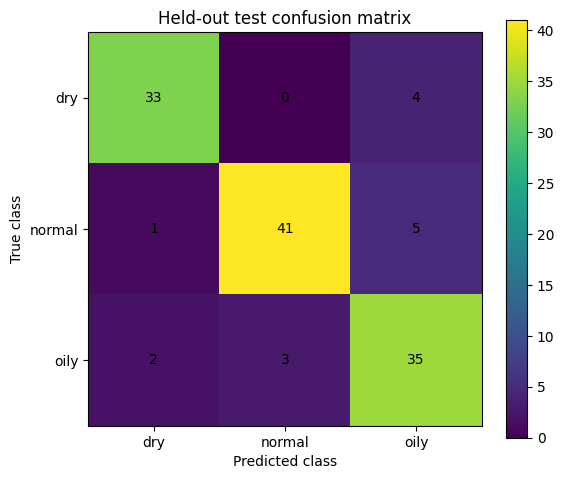

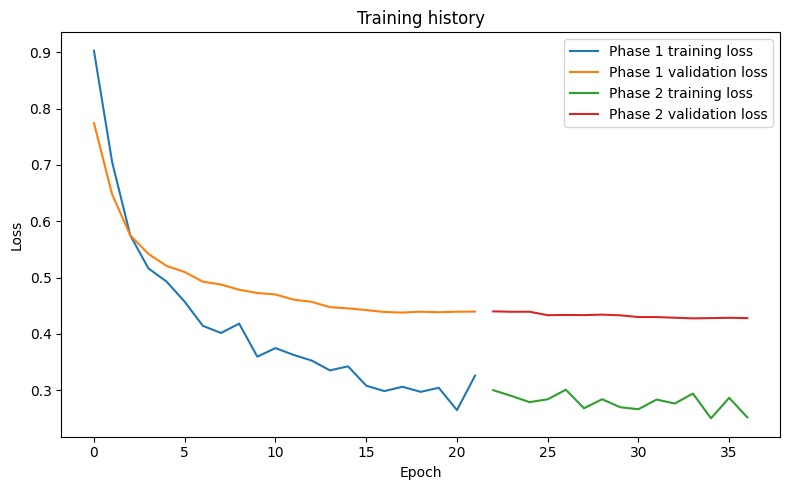


Saved artifacts:
 - evaluation_report.json
 - metadata.json
 - phase1_best.weights.h5
 - phase1_selected.weights.h5
 - phase2_best.weights.h5
 - skin_type_model.keras
 - splits.csv
 - test_confusion_matrix.png
 - training_loss.png
 - training_state.json


In [36]:
# CELL 11 — CALIBRATION, FINAL EVALUATION, AND SAVING
import json
import platform
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from scipy.optimize import minimize_scalar
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)
from tensorflow import keras

OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FINAL_MODEL_PATH = OUTPUT_DIR / "skin_type_model.keras"
METADATA_PATH = OUTPUT_DIR / "metadata.json"
REPORT_PATH = OUTPUT_DIR / "evaluation_report.json"

if RUN_TRAINING:

    def stable_softmax(logits, temperature=1.0):
        logits = np.asarray(logits, dtype=np.float64)
        scaled = logits / max(float(temperature), 1e-6)
        scaled -= scaled.max(axis=1, keepdims=True)
        exp_values = np.exp(scaled)
        return exp_values / exp_values.sum(axis=1, keepdims=True)

    def calculate_nll(logits, labels, temperature=1.0):
        probabilities = np.clip(
            stable_softmax(logits, temperature), 1e-12, 1.0
        )
        labels = np.asarray(labels, dtype=np.int64)
        return float(
            -np.log(probabilities[np.arange(len(labels)), labels]).mean()
        )

    def calculate_ece(labels, probabilities, bins=10):
        labels = np.asarray(labels, dtype=np.int64)
        confidence = probabilities.max(axis=1)
        predictions = probabilities.argmax(axis=1)
        correct = (predictions == labels).astype(float)
        edges = np.linspace(0.0, 1.0, bins + 1)
        ece = 0.0

        for i in range(bins):
            if i == bins - 1:
                mask = (confidence >= edges[i]) & (confidence <= edges[i + 1])
            else:
                mask = (confidence >= edges[i]) & (confidence < edges[i + 1])

            if mask.any():
                ece += mask.mean() * abs(
                    correct[mask].mean() - confidence[mask].mean()
                )
        return float(ece)

    def get_logits(images):
        images = np.asarray(images, dtype=np.float32)
        assert_model_input_range(images)
        return model.predict(
            images, batch_size=BATCH_SIZE, verbose=0
        )

    # ---------------------------------------------------------
    # 1. CALIBRATE ON VALIDATION DATA ONLY
    # ---------------------------------------------------------
    val_labels = np.asarray(y_val, dtype=np.int64)
    val_logits = get_logits(X_val_uint8)

    temperature_result = minimize_scalar(
        lambda temperature: calculate_nll(
            val_logits, val_labels, temperature
        ),
        bounds=(0.05, 10.0),
        method="bounded"
    )
    temperature = float(temperature_result.x)

    val_probabilities = stable_softmax(val_logits, temperature)
    val_predictions = val_probabilities.argmax(axis=1)
    val_confidence = val_probabilities.max(axis=1)

    # Select a threshold meeting the validation accuracy target
    # while retaining at least 50% coverage, where possible.
    target_accuracy = 0.90
    minimum_coverage = 0.50
    candidates = np.unique(
        np.concatenate(([0.0], val_confidence, [1.0]))
    )
    eligible = []

    for threshold in candidates:
        accepted = val_confidence >= threshold
        coverage = float(accepted.mean())

        if accepted.any() and coverage >= minimum_coverage:
            accepted_accuracy = float(
                accuracy_score(
                    val_labels[accepted], val_predictions[accepted]
                )
            )
            if accepted_accuracy >= target_accuracy:
                eligible.append(
                    (float(threshold), coverage, accepted_accuracy)
                )

    if eligible:
        # Highest coverage among thresholds that meet the target.
        confidence_threshold = max(eligible, key=lambda x: x[1])[0]
    else:
        # If the target is unattainable, retain coverage and maximize
        # accepted validation accuracy instead.
        fallback = []
        for threshold in candidates:
            accepted = val_confidence >= threshold
            if accepted.any() and accepted.mean() >= minimum_coverage:
                acc = accuracy_score(
                    val_labels[accepted], val_predictions[accepted]
                )
                fallback.append(
                    (float(threshold), float(acc), float(accepted.mean()))
                )
        confidence_threshold = (
            max(fallback, key=lambda x: (x[1], x[2]))[0]
            if fallback else 0.0
        )

    print(f"Selected temperature: {temperature:.4f}")
    print(f"Selected confidence threshold: {confidence_threshold:.4f}")
    print(
        "Validation NLL before calibration:",
        round(calculate_nll(val_logits, val_labels, 1.0), 4)
    )
    print(
        "Validation NLL after calibration:",
        round(calculate_nll(val_logits, val_labels, temperature), 4)
    )

    # ---------------------------------------------------------
    # 2. SAVE THE SELECTED MODEL
    # ---------------------------------------------------------
    model.save(str(FINAL_MODEL_PATH))
    print("Saved selected model:", FINAL_MODEL_PATH)

    # ---------------------------------------------------------
    # 3. EVALUATION HELPER
    # ---------------------------------------------------------
    def evaluate_dataset(split_name, images, labels):
        labels = np.asarray(labels, dtype=np.int64)
        logits = get_logits(images)

        raw_probabilities = stable_softmax(logits, 1.0)
        probabilities = stable_softmax(logits, temperature)
        predictions = probabilities.argmax(axis=1)
        confidence = probabilities.max(axis=1)
        accepted = confidence >= confidence_threshold

        precision, recall, f1, _ = precision_recall_fscore_support(
            labels,
            predictions,
            labels=list(range(len(CLASS_NAMES))),
            average="macro",
            zero_division=0
        )

        cm = confusion_matrix(
            labels, predictions,
            labels=list(range(len(CLASS_NAMES)))
        )

        report = classification_report(
            labels,
            predictions,
            labels=list(range(len(CLASS_NAMES))),
            target_names=list(CLASS_NAMES),
            output_dict=True,
            zero_division=0
        )

        results = {
            "split": split_name,
            "sample_count": int(len(labels)),
            "accuracy": float(accuracy_score(labels, predictions)),
            "macro_precision": float(precision),
            "macro_recall": float(recall),
            "macro_f1": float(f1),
            "nll_raw": calculate_nll(logits, labels, 1.0),
            "nll_calibrated": calculate_nll(
                logits, labels, temperature
            ),
            "ece_raw": calculate_ece(labels, raw_probabilities),
            "ece_calibrated": calculate_ece(labels, probabilities),
            "mean_confidence_raw": float(raw_probabilities.max(axis=1).mean()),
            "mean_confidence_calibrated": float(confidence.mean()),
            "confidence_threshold": float(confidence_threshold),
            "accepted_count": int(accepted.sum()),
            "coverage": float(accepted.mean()),
            "accepted_accuracy": (
                float(accuracy_score(labels[accepted], predictions[accepted]))
                if accepted.any() else None
            ),
            "confusion_matrix": cm.tolist(),
            "classification_report": report
        }

        print(f"\n{'=' * 18} {split_name.upper()} {'=' * 18}")
        print(f"Accuracy:       {results['accuracy']:.4f}")
        print(f"Macro precision: {results['macro_precision']:.4f}")
        print(f"Macro recall:    {results['macro_recall']:.4f}")
        print(f"Macro F1:        {results['macro_f1']:.4f}")
        print(
            f"ECE raw/calibrated: {results['ece_raw']:.4f} / "
            f"{results['ece_calibrated']:.4f}"
        )
        print(f"Confidence coverage: {results['coverage']:.1%}")
        print("\nPer-class report:")
        print(classification_report(
            labels,
            predictions,
            labels=list(range(len(CLASS_NAMES))),
            target_names=list(CLASS_NAMES),
            zero_division=0
        ))

        return results, cm

    # Validation metrics are useful for calibration diagnostics.
    validation_results, _ = evaluate_dataset(
        "validation", X_val_uint8, y_val
    )

    # Test set is evaluated only after model selection/calibration.
    test_results, test_cm = evaluate_dataset(
        "test", X_test_uint8, y_test
    )

    # ---------------------------------------------------------
    # 4. SAVE METADATA AND REPORT
    # ---------------------------------------------------------
    metadata = {
        "project": "Realtime Skin Analyst",
        "architecture": "EfficientNetV2B0",
        "class_names": list(CLASS_NAMES),
        "label_order": {
            name: index for index, name in enumerate(CLASS_NAMES)
        },
        "input_shape": list(INPUT_SHAPE),
        "input_color_space": "RGB",
        "input_dtype": "float32",
        "input_pixel_range": [0, 255],
        "preprocessing": (
            "EfficientNetV2B0 include_preprocessing=True; "
            "do not divide input pixels by 255"
        ),
        "model_output": "raw_logits",
        "temperature": temperature,
        "confidence_threshold": float(confidence_threshold),
        "margin_threshold": 0.15,
        "selected_phase": int(selected_phase),
        "quick_mode": bool(QUICK_MODE),
        "weights_setting": str(WEIGHTS),
        "python_version": platform.python_version(),
        "tensorflow_version": tf.__version__,
        "keras_version": keras.__version__
    }

    with open(METADATA_PATH, "w", encoding="utf-8") as f:
        json.dump(metadata, f, indent=2)

    with open(REPORT_PATH, "w", encoding="utf-8") as f:
        json.dump({
            "validation": validation_results,
            "test": test_results,
            "calibration": {
                "temperature": temperature,
                "confidence_threshold": float(confidence_threshold),
                "target_accuracy": target_accuracy,
                "minimum_coverage": minimum_coverage
            }
        }, f, indent=2)

    # ---------------------------------------------------------
    # 5. SAVE TEST CONFUSION MATRIX
    # ---------------------------------------------------------
    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(test_cm)
    ax.set_xticks(range(len(CLASS_NAMES)))
    ax.set_yticks(range(len(CLASS_NAMES)))
    ax.set_xticklabels(CLASS_NAMES)
    ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_title("Held-out test confusion matrix")

    for row in range(test_cm.shape[0]):
        for col in range(test_cm.shape[1]):
            ax.text(
                col, row, str(test_cm[row, col]),
                ha="center", va="center"
            )

    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / "test_confusion_matrix.png",
        dpi=160, bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    # ---------------------------------------------------------
    # 6. SAVE TRAINING CURVES WHEN HISTORY IS AVAILABLE
    # ---------------------------------------------------------
    fig, ax = plt.subplots(figsize=(8, 5))
    has_curve = False

    if phase1_history is not None:
        ax.plot(
            phase1_history.get("loss", []),
            label="Phase 1 training loss"
        )
        ax.plot(
            phase1_history.get("val_loss", []),
            label="Phase 1 validation loss"
        )
        has_curve = True

    if phase2_history is not None:
        offset = (
            len(phase1_history.get("loss", []))
            if phase1_history is not None else 0
        )
        epochs = np.arange(
            offset, offset + len(phase2_history.get("loss", []))
        )
        ax.plot(
            epochs, phase2_history.get("loss", []),
            label="Phase 2 training loss"
        )
        ax.plot(
            epochs, phase2_history.get("val_loss", []),
            label="Phase 2 validation loss"
        )
        has_curve = True

    if has_curve:
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.set_title("Training history")
        ax.legend()
        fig.tight_layout()
        fig.savefig(
            OUTPUT_DIR / "training_loss.png",
            dpi=160, bbox_inches="tight"
        )
        plt.show()

    plt.close(fig)

    print("\nSaved artifacts:")
    for file_path in sorted(OUTPUT_DIR.iterdir()):
        if file_path.is_file():
            print(" -", file_path.name)

else:
    print("RUN_TRAINING=False — calibration and evaluation skipped.")

In [37]:

import numpy as np
import cv2
import json
from pathlib import Path

# Reuse the calibrated values from Cell 11 when available.
# Otherwise, use safe defaults.
TEMPERATURE_FOR_INFERENCE = float(
    globals().get("temperature", globals().get("best_temperature", 1.0))
)

CONFIDENCE_THRESHOLD_FOR_INFERENCE = float(
    globals().get("confidence_threshold", 0.0)
)

def predict_skin_type(image_rgb):
    """
    Input:
        RGB image as a NumPy array, with pixel values in [0, 255].

    Output:
        Predicted skin-type label, confidence and class probabilities.
    """
    image_rgb = np.asarray(image_rgb)

    if image_rgb.ndim != 3 or image_rgb.shape[2] != 3:
        raise ValueError("Expected an RGB image with shape (height, width, 3).")

    if image_rgb.dtype != np.uint8:
        image_rgb = np.clip(image_rgb, 0, 255).astype(np.uint8)

    resized = cv2.resize(
        image_rgb,
        (IMAGE_WIDTH, IMAGE_HEIGHT),
        interpolation=cv2.INTER_AREA
    )

    batch = np.expand_dims(resized.astype(np.float32), axis=0)

    # Model outputs raw logits; temperature scaling calibrates probabilities.
    logits = np.asarray(model.predict(batch, verbose=0))[0]
    scaled_logits = logits / max(TEMPERATURE_FOR_INFERENCE, 1e-6)
    scaled_logits -= np.max(scaled_logits)

    probabilities = np.exp(scaled_logits)
    probabilities /= probabilities.sum()

    predicted_index = int(np.argmax(probabilities))
    confidence = float(probabilities[predicted_index])
    predicted_label = CLASS_NAMES[predicted_index]

    return {
        "skin_type": predicted_label,
        "confidence": confidence,
        "probabilities": {
            CLASS_NAMES[i]: float(probabilities[i])
            for i in range(len(CLASS_NAMES))
        },
        "below_confidence_threshold": (
            confidence < CONFIDENCE_THRESHOLD_FOR_INFERENCE
        )
    }

print("Prediction function is ready.")
print("Classes:", CLASS_NAMES)
print("Temperature:", TEMPERATURE_FOR_INFERENCE)
print("Confidence threshold:", CONFIDENCE_THRESHOLD_FOR_INFERENCE)


Prediction function is ready.
Classes: ('dry', 'normal', 'oily')
Temperature: 1.176561051768773
Confidence threshold: 0.7406301421522385


2026-10-19 14:17:12.746891: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-19 14:17:12.882977: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


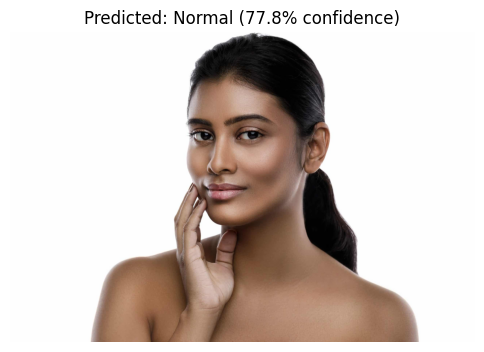

Prediction: Normal
Confidence: 77.77%

Class probabilities:
  Dry        4.83%
  Normal     77.77%
  Oily       17.40%


In [40]:

from PIL import Image
import matplotlib.pyplot as plt

# Replace this with the path to your test image.
IMAGE_PATH = "/kaggle/input/datasets/tejaswinirj/even-skin/even-skin-tone-scaled.jpeg"

image_path = Path(IMAGE_PATH)

if not image_path.exists():
    print("Image not found. Update IMAGE_PATH to a valid image file.")
else:
    image = Image.open(image_path).convert("RGB")
    image_rgb = np.array(image)

    result = predict_skin_type(image_rgb)

    plt.figure(figsize=(6, 5))
    plt.imshow(image_rgb)
    plt.axis("off")
    plt.title(
        f"Predicted: {result['skin_type'].title()} "
        f"({result['confidence']:.1%} confidence)"
    )
    plt.show()

    print("Prediction:", result["skin_type"].title())
    print(f"Confidence: {result['confidence']:.2%}")
    print("\nClass probabilities:")

    for label, probability in result["probabilities"].items():
        print(f"  {label.title():<10} {probability:.2%}")

    if result["below_confidence_threshold"]:
        print(
            "\nLow-confidence prediction: treat this result as uncertain "
            "and try a clearer image."
        )
